# The liquefier's three frames: lab, bjorken and fluid

X-SCAPE's CausalLiquefier turns what a jet loses to the medium into **droplets**: points in
space-time carrying a four-momentum, which a causal (telegraph) diffusion spreads into MUSIC's
fluid on the slice $\tau_d + \tau_\text{delay}$. The diffusion is solved in some frame, and
which one matters: tutorial 06 found that a droplet made at forward rapidity ($\eta_s = 2.4$,
$\tau \approx 1$ fm/c) leaves almost no trace in the fluid. This notebook compares the three
frames `<CausalLiquefier><frame>` offers, on the same 25 events:

| frame | the diffusion is solved in | X-SCAPE |
|---|---|---|
| `lab` | the collision's frame, as in the liquefier's paper (arXiv:2001.08321, for a medium with small flow) | before 2026-11 |
| `bjorken` | the frame of the Bjorken flow at the droplet's $\eta_s$: a longitudinal boost by $\eta_d$ | the default |
| `fluid` | the rest frame of the background fluid where the droplet was made, transverse flow included | new |

**The data** come from `make_data.sh` (this directory): tutorial 06's event (0–10% Au+Au at
200 GeV, seed 101, one background, PYTHIA $\hat p_T$ = 30–40 GeV, hard partons at $|y| < 0.6$)
with 25 jets instead of 5, in each frame, hadronized with correlated sampling (200 samples).
The background, the jets and the droplets are bit-identical in the three runs: only the
deposit differs. `frame_summary.py` reduces them to `summary.npz`, which this notebook reads
(it runs the summary itself if the file is missing).

**Contents.** 1 · One droplet in the three frames · 2 · The droplets and the fluid they are
made in · 3 · Energy conservation · 4 · Where the energy goes · 5 · Wake observables · 6 · Summary

In [1]:
import ast
import os
import sys
import warnings

import hist
import matplotlib.pyplot as plt
import mplhep as hep
import numpy as np

warnings.filterwarnings("ignore", "All-NaN slice")   # frames after a run's last stored one
sys.path.insert(0, os.getcwd())                 # liquefier_kernel.py, frame_summary.py
import liquefier_kernel as lk

DATA = os.environ.get("LFT_DATA", os.path.expanduser("~/JetScape/liquefier_frame_test"))
SUMMARY = os.path.join(DATA, "summary.npz")
if not os.path.exists(SUMMARY):
    import frame_summary
    frame_summary.main([DATA])
z = np.load(SUMMARY)
FRAMES = [str(f) for f in z["frames"]]
COL = {"lab": "C3", "bjorken": "C0", "fluid": "C2"}
drops, fluid, ev = z["drops"], z["fluid"], z["ev"]
E = drops[:, 4]
DC = [str(c) for c in z["dep_columns"]]
dep = {fr: z[f"dep/{fr}"] for fr in ("lab", "bjorken", "fluid")}
col = lambda fr, name: dep[fr][:, DC.index(name)]
nev = len(z["offsets"]) - 1
# each run stored its own number of tau frames (the longest-lived jet leg): one common axis
NT = max(z[f"{fr}/dE_full"].shape[1] for fr in FRAMES)
tau = z["tau"][0] + (z["tau"][1] - z["tau"][0]) * np.arange(NT)

def series(fr, key):
    # (events, NT) of a per-tau summary, NaN where that run stored no frame
    a = z[f"{fr}/{key}"]
    out = np.full((a.shape[0], NT), np.nan)
    out[:, :a.shape[1]] = a
    return out
TAU_DELAY = 1.0
print(f"{nev} events, {len(drops)} droplets, {E.sum():.0f} GeV; frames {FRAMES}")
print("checks:", ast.literal_eval(str(z["checks"])))

25 events, 578 droplets, 974 GeV; frames ['lab', 'bjorken', 'fluid']
checks: {'droplets_identical': True, 'backgrounds_identical': True, 'fluid_from': 'file'}


## 1. One droplet in the three frames

The kernel is the same in every frame: a density $\rho(t, r)$ and a radial current
$j(t, r)$ that spread from the droplet at the signal speed $c = \sqrt{D/\tau_r} \approx 0.9$, with
a wave front of width 0.1 fm. What changes is the frame they are evaluated in:

- **lab**: $t$ and $r$ are the lab age and distance. On the slice $\tau_d + \tau_\text{delay}$
  a forward droplet is barely aged (the slice reaches its $\eta_s$ early in lab time), and the
  deposit is squeezed and pulled toward midrapidity.
- **bjorken**: boost by $\eta_d$ first. Every droplet then deposits as one at $\eta_s = 0$ does,
  shifted to its $\eta_d$.
- **fluid**: boost by $\eta_d$, then by the fluid's velocity relative to the Bjorken flow,
  $\vec v$ (mostly transverse). The cell–droplet separation is boosted into the fluid's rest
  frame, $\rho$ and $j$ are evaluated at that age and distance, the current is boosted back,
  and its flux through the $\tau$ slice is deposited. The deposit is carried along the flow
  and contracted along it by $\gamma = 1/\sqrt{1 - v^2}$.

In all three the flux through the slice is 1 (a conserved current), and MUSIC normalizes each
droplet exactly on its grid. Below, two droplets of these events on a fine grid ($x$ against
$\eta_s$, summed over $y$): the most energetic forward one, and the one made in the fastest
flowing fluid.

droplet 408 (event 18): tau_d 2.38 fm/c, x 4.9, y -0.9 fm, eta_d 2.35, E 18.8 GeV; fluid e 1.19 GeV/fm^3, v_lab (0.06, -0.00, 0.98), v relative to the Bjorken flow (0.35, -0.02, 0.06), |v| = 0.36


droplet 143 (event 7): tau_d 5.29 fm/c, x 5.9, y 6.4 fm, eta_d -0.59, E 6.6 GeV; fluid e 0.13 GeV/fm^3, v_lab (0.46, 0.44, -0.52), v relative to the Bjorken flow (0.54, 0.52, 0.01), |v| = 0.75


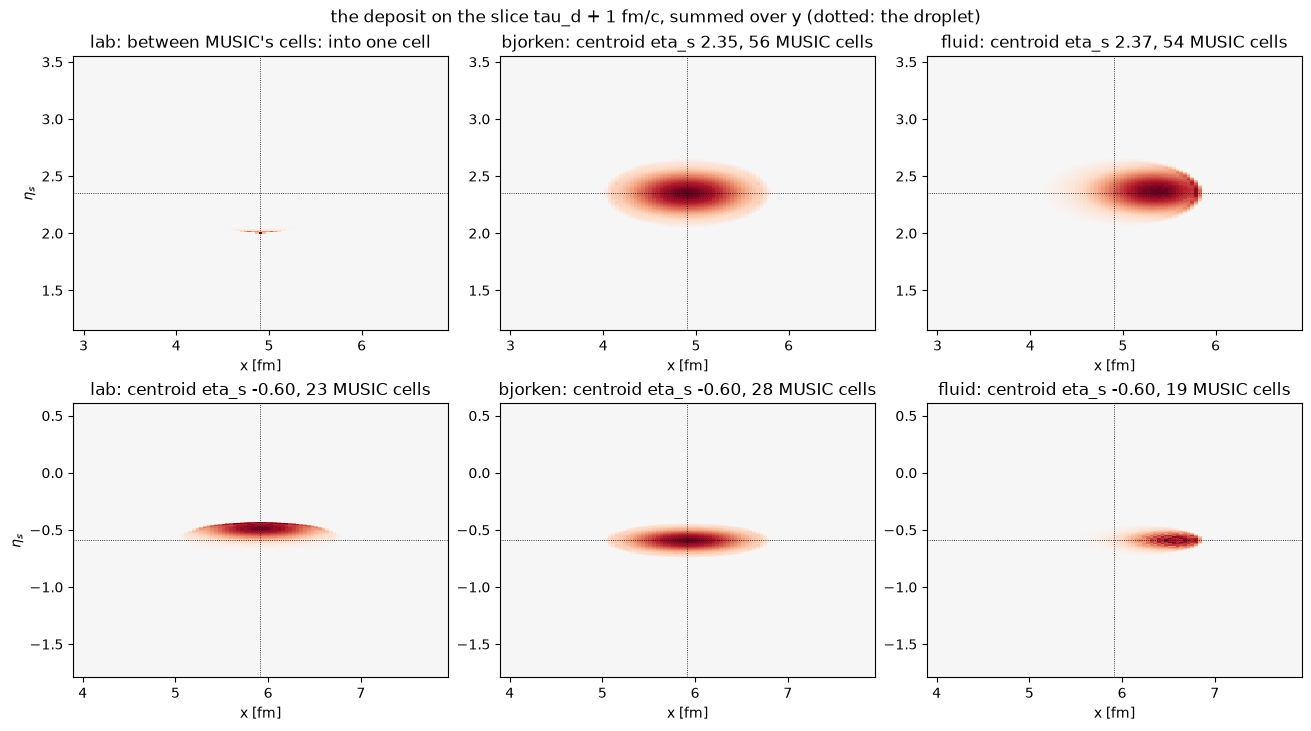

In [2]:
k = lk.Kernel(**lk.PARAMS)
vrel = np.array([lk.relative_velocity(d[3], f, float(z["e_min"])) for d, f in zip(drops, fluid)])
speed = np.linalg.norm(vrel, axis=1)
i_fwd = int(np.argmax(np.where(np.abs(drops[:, 3]) > 1.8, E, -np.inf)))
i_flow = int(np.argmax(np.where(E > 1.0, speed, -np.inf)))
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), constrained_layout=True)
for row, i in enumerate((i_fwd, i_flow)):
    d = drops[i]
    tq = d[0] + TAU_DELAY
    fine = dict(x_min=d[1] - 2.0, dx=0.04, nx=101, y_min=d[2] - 2.0, dy=0.04, ny=101,
                eta_min=d[3] - 1.2, deta=0.01, neta=241)
    xs = fine["x_min"] + fine["dx"] * np.arange(fine["nx"])
    for ax, fr in zip(axes[row], ("lab", "bjorken", "fluid")):
        w, _, etas, _ = k.deposit(d, fine, fr, tau_q=tq, fluid=fluid[i])
        img = w.sum(axis=2)                       # (eta, x)
        m = np.abs(img).max()
        ax.pcolormesh(xs, etas, img, cmap="RdBu_r", vmin=-m, vmax=m, shading="nearest")
        nat = lk.summary(*k.deposit(d, lk.NATIVE, fr, tau_q=tq, fluid=fluid[i]))
        ax.axhline(d[3], color="k", lw=0.6, ls=":")
        ax.axvline(d[1], color="k", lw=0.6, ls=":")
        what = (f"centroid eta_s {nat['mean']:.2f}, {nat['cells']} MUSIC cells" if nat["cells"]
                else "between MUSIC's cells: into one cell")
        ax.set(title=f"{fr}: {what}",
               xlabel="x [fm]", ylim=(d[3] - 1.2, d[3] + 1.2))
    axes[row, 0].set_ylabel(r"$\eta_s$")
    vx, vy, vz, e = fluid[i]
    print(f"droplet {i} (event {ev[i]}): tau_d {d[0]:.2f} fm/c, x {d[1]:.1f}, y {d[2]:.1f} fm, "
          f"eta_d {d[3]:.2f}, E {d[4]:.1f} GeV; fluid e {e:.2f} GeV/fm^3, v_lab ({vx:.2f}, {vy:.2f}, "
          f"{vz:.2f}), v relative to the Bjorken flow ({vrel[i, 0]:.2f}, {vrel[i, 1]:.2f}, "
          f"{vrel[i, 2]:.2f}), |v| = {speed[i]:.2f}")
fig.suptitle("the deposit on the slice tau_d + 1 fm/c, summed over y (dotted: the droplet)");

**What to notice.**

- **The forward droplet** (18.8 GeV, made at $\eta_s = 2.35$, $\tau = 2.4$ fm/c). In the
  **lab** frame the slice reaches it after 0.4 fm/c of lab time instead of 1: the cloud is a
  sliver 0.01 wide in $\eta_s$, pulled to $\eta_s \approx 2.0$, and falls between MUSIC's cell
  centres. The C++ then puts the whole droplet into one cell. In the **bjorken** frame it
  deposits as a midrapidity droplet does, centred on its own $\eta_s$, over 56 cells.
- **The fluid frame** carries the same cloud with the fluid. Here the fluid moves at 0.36
  relative to the Bjorken flow, along $+x$, outward. The cloud's centre moves about 0.4 fm
  that way, its front ahead is sharpened, and it still covers 54 cells.
- **The fast-flow droplet** (made late, at $\tau = 5.3$ fm/c, in dilute fluid with $|\vec v| = 0.75$)
  is shifted by about 0.6 fm along the flow and contracted, over 19 cells against 28 in the
  Bjorken frame. Along $\eta_s$, bjorken and fluid are the same: the flow relative to the
  Bjorken flow is almost purely transverse.

## 2. The droplets and the fluid they are made in

Each droplet carries the background fluid where it was made (`source/fluid` of the fluid
run: the lab velocity and the energy density of MUSIC_1's cell, the medium Matter and LBT
see). The fluid frame boosts by its velocity relative to the Bjorken flow, $\vec v$. A droplet
without a usable fluid, $e < e_\text{min} = 0.1$ GeV/fm$^3$ (made before the hydro starts at
$\tau_0 = 0.4$ fm/c, or outside the fireball), takes the Bjorken frame.

droplets: 578, 1118 GeV (|E|); with E < 0: 91
  in the Bjorken frame (no fluid): 52 (67.8 GeV), of them made before tau0: 47
  |v| relative to the Bjorken flow, energy-weighted: mean 0.28, max 0.75; above 0.5: 84 droplets (207.9 GeV)


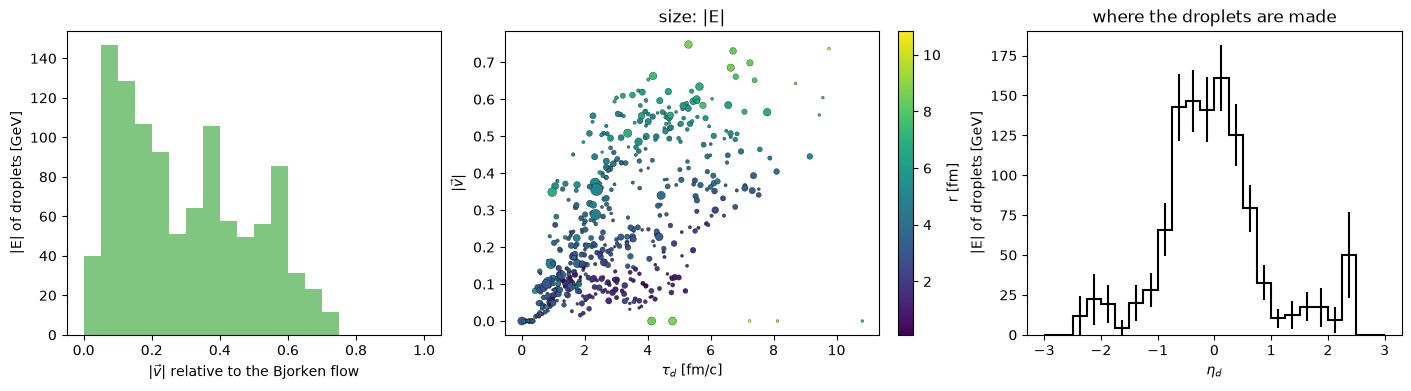

In [3]:
fallback = ~(fluid[:, 3] >= float(z["e_min"]))
early = drops[:, 0] < z["tau0"][ev]
print(f"droplets: {len(drops)}, {np.abs(E).sum():.0f} GeV (|E|); with E < 0: {(E < 0).sum()}")
print(f"  in the Bjorken frame (no fluid): {fallback.sum()} ({np.abs(E[fallback]).sum():.1f} GeV), "
      f"of them made before tau0: {(fallback & early).sum()}")
print(f"  |v| relative to the Bjorken flow, energy-weighted: mean {np.average(speed, weights=np.abs(E)):.2f}, "
      f"max {speed.max():.2f}; above 0.5: {(speed > 0.5).sum()} droplets ({np.abs(E[speed > 0.5]).sum():.1f} GeV)")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
h = hist.Hist(hist.axis.Regular(20, 0, 1, name="v", label=r"$|\vec v|$ relative to the Bjorken flow"),
              storage=hist.storage.Weight())
h.fill(speed[~fallback], weight=np.abs(E[~fallback]))
hep.histplot(h, ax=axes[0], histtype="fill", alpha=0.6, color=COL["fluid"])
axes[0].set(ylabel="|E| of droplets [GeV]")
sc = axes[1].scatter(drops[:, 0], speed, s=4 + 4 * np.abs(E), c=np.hypot(drops[:, 1], drops[:, 2]),
                     cmap="viridis", edgecolors="k", linewidths=0.2)
fig.colorbar(sc, ax=axes[1], label="r [fm]")
axes[1].set(xlabel=r"$\tau_d$ [fm/c]", ylabel=r"$|\vec v|$", title="size: |E|")
h2 = hist.Hist(hist.axis.Regular(24, -3, 3, name="eta", label=r"$\eta_d$"), storage=hist.storage.Weight())
h2.fill(drops[:, 3], weight=np.abs(E))
hep.histplot(h2, ax=axes[2], color="k")
axes[2].set(ylabel="|E| of droplets [GeV]", title="where the droplets are made");

**What to notice.**

- **The droplets.** 578 droplets carry 1118 GeV (|E|; 91 have negative energy: momentum
  transfers, not particles). 52 droplets with 68 GeV take the Bjorken frame, 47 of them made
  before the hydro starts.
- **The fluid's speed relative to the Bjorken flow** is modest: 0.28 on average (energy
  weighted) and at most 0.75. That is far from the cap of 0.99, so no droplet is capped. Speeds
  above 0.5 (84 droplets, 208 GeV) occur late and at large radius, where the radial flow has
  built up: the fluid frame matters most for late deposits.

## 3. Energy conservation

### 3.1 What MUSIC's grid catches

Before normalization, a droplet's kernel sampled at MUSIC's cell centres sums to its
**flux** (`source/flux`, from the C++). MUSIC divides by it, so every droplet deposits exactly
its four-momentum; but a flux far from 1 means the kernel is badly resolved by the grid, and the
normalization then rescales a few cells.

lab     : flux median 1.01; |E| with flux < 0.5 or > 1.5: 239.3 GeV of 1112; into one cell: 3
bjorken : flux median 1.01; |E| with flux < 0.5 or > 1.5:  32.4 GeV of 1118; into one cell: 0
fluid   : flux median 1.00; |E| with flux < 0.5 or > 1.5:  55.0 GeV of 1118; into one cell: 0


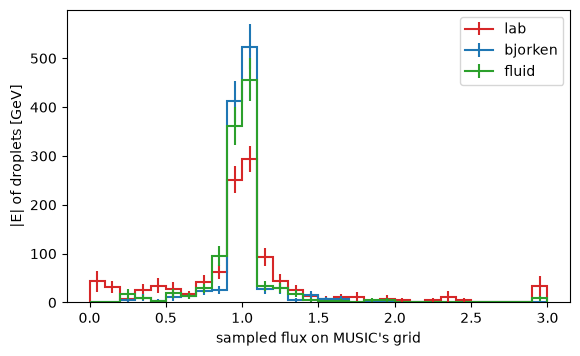

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for fr in FRAMES:
    fl = z[f"{fr}/flux"]
    m = fl > 0
    h = hist.Hist(hist.axis.Regular(30, 0, 3, name="flux", label="sampled flux on MUSIC's grid"),
                  storage=hist.storage.Weight())
    h.fill(np.clip(fl[m], 0, 2.999), weight=np.abs(E[m]))
    hep.histplot(h, ax=ax, label=fr, color=COL[fr])
    off = (fl < 0.5) | (fl > 1.5)
    print(f"{fr:8s}: flux median {np.median(fl[m]):.2f}; |E| with flux < 0.5 or > 1.5: "
          f"{np.abs(E[off & m]).sum():5.1f} GeV of {np.abs(E[m]).sum():.0f}; into one cell: {(fl == 0).sum()}")
ax.set(ylabel="|E| of droplets [GeV]"); ax.legend();

**What to notice.**

- **The lab frame is badly resolved.** 239 of 1112 GeV (21 %) sit in droplets whose
  sampled flux is below 0.5 or above 1.5, and 3 droplets miss every cell centre. These are the
  thin forward clouds of section 1.
- **The Bjorken and fluid frames** are well resolved: 3 % and 5 % of the energy. The fluid
  frame's slightly larger share comes from its contraction along the flow.

### 3.2 Cells MUSIC cannot invert

A droplet is a momentum transfer, $p_\text{in} - \sum p_\text{out}$, often spacelike. Where its
deposit dominates a cell, the cell's $|\vec M| = |T^{\tau i}|$ can exceed $T^{\tau\tau}$; MUSIC
(CPU and GPU) then cannot find a fluid with that $T^{\tau\mu}$, reverts the cell and **discards
the deposit**. `frame_summary.py` applies each droplet's deposit (the Python port, on MUSIC's
grid) to the background interpolated from `arr_bg` and counts the energy landing in cells left
with $T^{\tau\tau} \le |\vec M|$. It is an estimate: one droplet at a time, the background at the
stored frame nearest the deposit.

frame     |E| into uninvertible cells   worst droplets (event, eta_d, tau_d, E: share)
lab          39.4 of 1112 GeV ( 3.5%)   (0, 2.4, 0.8, 12.9: 1.00), (18, 2.3, 2.3, -5.0: 1.00), (22, -1.8, 0.7, -5.9: 0.82)
bjorken       4.7 of 1118 GeV ( 0.4%)   (21, -0.6, 4.2, -3.2: 0.76), (12, -0.6, 4.6, -1.3: 0.61), (0, -0.6, 8.1, 3.4: 0.14)
fluid        17.5 of 1118 GeV ( 1.6%)   (21, -0.6, 4.2, -3.2: 0.86), (0, -0.6, 8.1, 3.4: 0.47), (8, 0.7, 5.8, 2.5: 0.57)


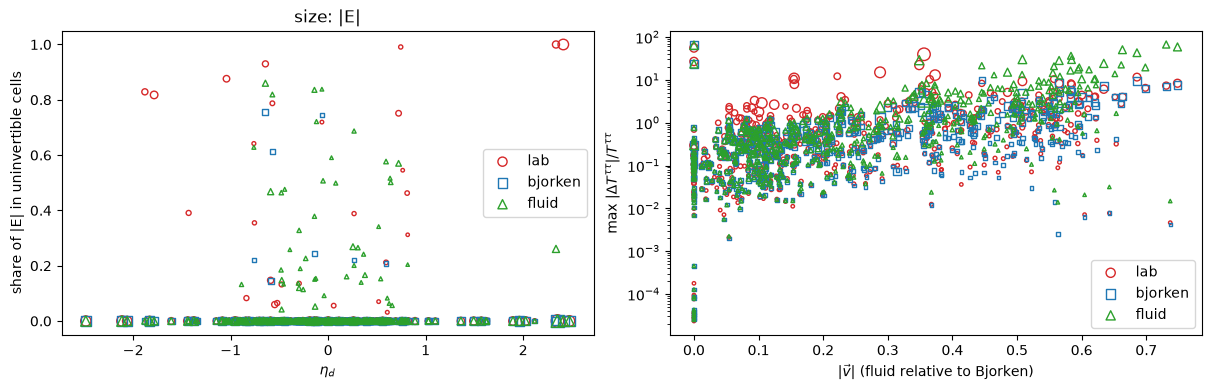

In [5]:
print(f"{'frame':8s} {'|E| into uninvertible cells':>28s}   worst droplets (event, eta_d, tau_d, E: share)")
for fr in ("lab", "bjorken", "fluid"):
    b = col(fr, "bad_share")
    m = np.isfinite(b)
    worst = np.argsort(np.where(m, b * np.abs(E), -1))[::-1][:3]
    w = ", ".join(f"({ev[i]}, {drops[i, 3]:.1f}, {drops[i, 0]:.1f}, {E[i]:.1f}: {b[i]:.2f})" for i in worst if b[i] > 0)
    print(f"{fr:8s} {np.nansum(b * np.abs(E)):8.1f} of {np.abs(E[m]).sum():.0f} GeV ({np.nansum(b * np.abs(E)) / np.abs(E[m]).sum():5.1%})   {w}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for fr, mk in (("lab", "o"), ("bjorken", "s"), ("fluid", "^")):
    b = col(fr, "bad_share")
    axes[0].scatter(drops[:, 3], b, s=6 + 4 * np.abs(E), marker=mk, facecolors="none",
                    edgecolors=COL[fr], label=fr)
    axes[1].scatter(speed, col(fr, "max_ratio"), s=6 + 4 * np.abs(E), marker=mk,
                    facecolors="none", edgecolors=COL[fr], label=fr)
axes[0].set(xlabel=r"$\eta_d$", ylabel="share of |E| in uninvertible cells", title="size: |E|")
axes[1].set(xlabel=r"$|\vec v|$ (fluid relative to Bjorken)", ylabel=r"max $|\Delta T^{\tau\tau}| / T^{\tau\tau}$",
            yscale="log")
axes[0].legend(); axes[1].legend();

**What to notice.**

- **The lab frame** sends 3.5 % of the droplets' energy into cells MUSIC cannot invert. The
  worst cases are early, forward droplets: event 0's 12.9 GeV droplet at $\eta_s = 2.4$
  entirely, as found before for the 5-event set.
- **The Bjorken frame** sends 0.4 %. What remains are late droplets ($\tau_d$ = 4–8 fm/c)
  with negative energy in dilute fluid near freeze-out.
- **The fluid frame** sends 1.6 %: the same late droplets, now contracted along the flow,
  hence denser. That is about four times the Bjorken frame, but small; it is the price of the
  rest frame where the flow is fast and the fluid thin.

### 3.3 Does the fluid keep what the droplets deposit?

As in tutorial 06: the fluid's lab energy through the $\tau$ surface, jet leg minus
background, against the energy of the droplets deposited by then ($\tau_d + 1$ fm/c), over the
whole stored grid and at $|\eta_s| < 1$ (there, the droplets made at $|\eta_d| < 1$). The count
uses the ideal part of $T^{\mu\nu}$: late, the shear stress adds a few percent that it leaves out.

lab      whole grid: tau 2: 0.904, tau 3: 0.948, tau 4: 0.972, tau 6: 0.987, tau 8: 0.973
bjorken  whole grid: tau 2: 1.004, tau 3: 1.003, tau 4: 0.992, tau 6: 0.997, tau 8: 0.982
fluid    whole grid: tau 2: 0.999, tau 3: 1.004, tau 4: 1.002, tau 6: 0.994, tau 8: 0.971


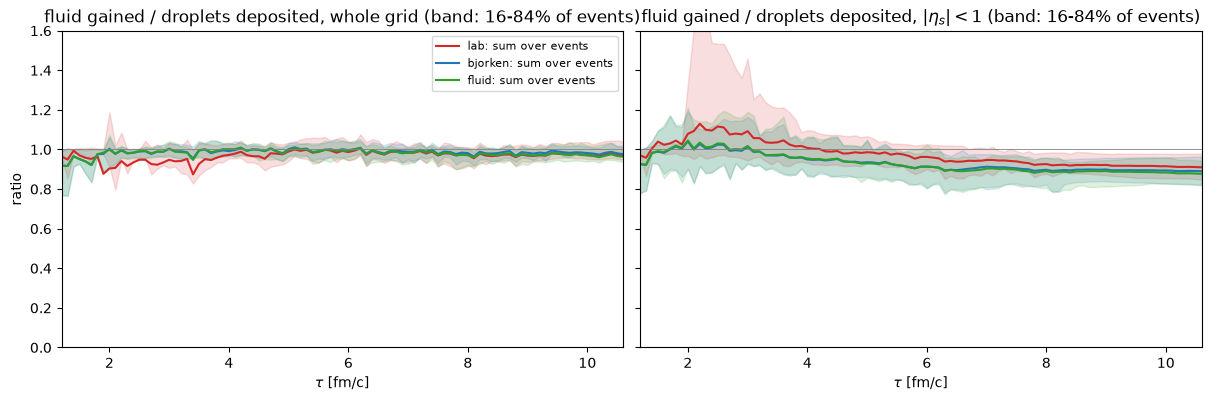

In [6]:
def deposited(t, window=None):
    out = np.zeros((nev, len(t)))
    for i in range(nev):
        d = drops[ev == i]
        m = np.ones(len(d), bool) if window is None else np.abs(d[:, 3]) < window
        out[i] = [d[m & (d[:, 0] + TAU_DELAY <= x), 4].sum() for x in t]
    return out

dep_full, dep_win = deposited(tau), deposited(tau, 1.0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), constrained_layout=True, sharey=True)
ratio_sum = {}
for ax, key, D, title in ((axes[0], "dE_full", dep_full, "whole grid"),
                          (axes[1], "dE_win", dep_win, r"$|\eta_s| < 1$")):
    for fr in FRAMES:
        G = series(fr, key)
        alive = np.isfinite(G).sum(axis=0) == nev            # all events still evolving
        r = np.nansum(G, axis=0) / np.maximum(D.sum(axis=0), 1e-9)
        per = G / np.where(D > 1, D, np.nan)
        lo, hi = np.nanpercentile(per, [16, 84], axis=0)
        ax.plot(tau[alive], r[alive], color=COL[fr], label=f"{fr}: sum over events")
        ax.fill_between(tau[alive], lo[alive], hi[alive], color=COL[fr], alpha=0.15)
        ratio_sum[(fr, key)] = (tau[alive], r[alive])
    ax.axhline(1, color="0.5", lw=0.6)
    ax.set(xlabel=r"$\tau$ [fm/c]", title=f"fluid gained / droplets deposited, {title} (band: 16-84% of events)",
           xlim=(1.2, tau[alive][-1]), ylim=(0, 1.6))
axes[0].set_ylabel("ratio"); axes[0].legend(fontsize=8)
for fr in FRAMES:
    t_, r_ = ratio_sum[(fr, "dE_full")]
    print(f"{fr:8s} whole grid: " + ", ".join(f"tau {x:.0f}: {r_[np.argmin(np.abs(t_ - x))]:.3f}" for x in (2, 3, 4, 6, 8)))

lab      tau = 3 fm/c, per event: min 0.54, median 0.98; events below 0.9: 4
bjorken  tau = 3 fm/c, per event: min 0.91, median 0.99; events below 0.9: 0
fluid    tau = 3 fm/c, per event: min 0.92, median 1.00; events below 0.9: 0


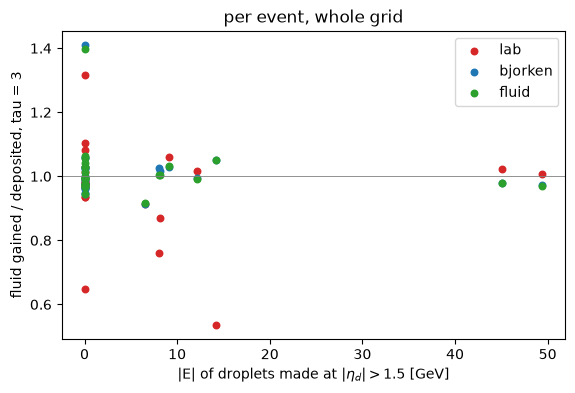

In [7]:
# event by event: the gain over the whole grid at tau = 3 fm/c, and the events whose droplets
# were made forward
k3 = int(np.argmin(np.abs(tau - 3.0)))
E_fwd = np.array([np.abs(E[(ev == i) & (np.abs(drops[:, 3]) > 1.5)]).sum() for i in range(nev)])
rat = {fr: series(fr, "dE_full")[:, k3] / dep_full[:, k3] for fr in FRAMES}
fig, ax = plt.subplots(figsize=(6.5, 4))
for fr in FRAMES:
    ax.scatter(E_fwd, rat[fr], color=COL[fr], label=fr, s=22)
ax.axhline(1, color="0.5", lw=0.6)
ax.set(xlabel=r"|E| of droplets made at $|\eta_d| > 1.5$ [GeV]", ylabel="fluid gained / deposited, tau = 3",
       title="per event, whole grid"); ax.legend()
for fr in FRAMES:
    print(f"{fr:8s} tau = 3 fm/c, per event: min {np.nanmin(rat[fr]):.2f}, median {np.nanmedian(rat[fr]):.2f}; "
          f"events below 0.9: {(rat[fr] < 0.9).sum()}")

**What to notice.**

- **Over the whole grid,** the Bjorken and fluid frames keep what is deposited, within 1 %
  from $\tau = 2$ to 6 fm/c. The lab frame keeps 0.90 at $\tau = 2$ and 0.95 at 3 fm/c.
- **Event by event,** the lab frame loses up to half the energy deposited by $\tau = 3$ fm/c
  (4 events below 0.9; the worst have most energy in forward droplets). In the other two
  frames no event falls below 0.91.
- **The late slow decline** to 0.97–0.98 is the same in all frames. It is the shear stress,
  which this count leaves out, as in tutorial 06.
- **At $|\eta_s| < 1$** the lab frame rises above 1 at $\tau$ = 2–3 fm/c: it pulls droplets made
  outside the window into it. Later all three fall to about 0.9 as the wake spreads out of the
  window.

## 4. Where the energy goes

### 4.1 The deposit of each droplet

The centroid and widths of each droplet's deposit on MUSIC's grid (the Python port), against
where it was made.

frame    |centroid - eta_d|  rms eta (median) r rms [fm]  cells age [fm/c]
lab                   0.160             0.098       0.52     45       1.00
bjorken               0.010             0.105       0.53     52       1.03
fluid                 0.017             0.101       0.52     50       1.01


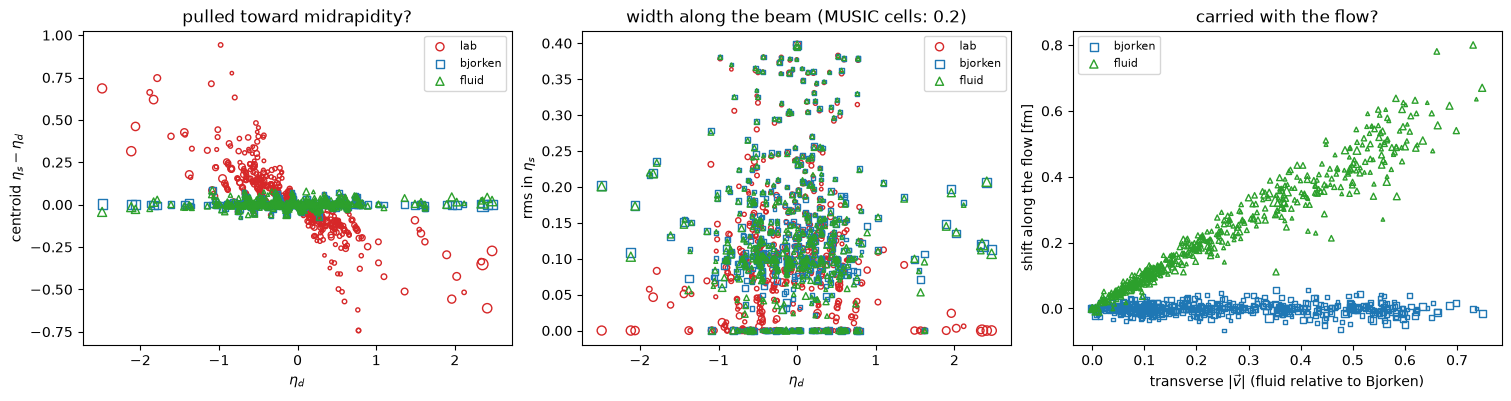

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), constrained_layout=True)
for fr, mk in (("lab", "o"), ("bjorken", "s"), ("fluid", "^")):
    s = 6 + 3 * np.abs(E)
    axes[0].scatter(drops[:, 3], col(fr, "eta_mean") - drops[:, 3], s=s, marker=mk, facecolors="none",
                    edgecolors=COL[fr], label=fr)
    axes[1].scatter(drops[:, 3], col(fr, "eta_rms"), s=s, marker=mk, facecolors="none", edgecolors=COL[fr], label=fr)
# the transverse shift along the flow (fluid against bjorken)
vT = np.hypot(vrel[:, 0], vrel[:, 1])
nhat = vrel[:, :2] / np.maximum(vT, 1e-12)[:, None]
for fr, mk in (("bjorken", "s"), ("fluid", "^")):
    shift = (col(fr, "x_mean") - drops[:, 1]) * nhat[:, 0] + (col(fr, "y_mean") - drops[:, 2]) * nhat[:, 1]
    axes[2].scatter(vT, shift, s=6 + 3 * np.abs(E), marker=mk, facecolors="none", edgecolors=COL[fr], label=fr)
axes[0].set(xlabel=r"$\eta_d$", ylabel=r"centroid $\eta_s - \eta_d$", title="pulled toward midrapidity?")
axes[1].set(xlabel=r"$\eta_d$", ylabel=r"rms in $\eta_s$", title="width along the beam (MUSIC cells: 0.2)")
axes[2].set(xlabel=r"transverse $|\vec v|$ (fluid relative to Bjorken)", ylabel="shift along the flow [fm]",
            title="carried with the flow?")
for a in axes: a.legend(fontsize=8)
print(f"{'frame':8s} {'|centroid - eta_d|':>18s} {'rms eta (median)':>17s} {'r rms [fm]':>10s} {'cells':>6s} {'age [fm/c]':>10s}")
for fr in ("lab", "bjorken", "fluid"):
    w = np.abs(E)
    m = np.isfinite(col(fr, "eta_mean"))
    print(f"{fr:8s} {np.average(np.abs(col(fr, 'eta_mean') - drops[:, 3])[m], weights=w[m]):18.3f} "
          f"{np.median(col(fr, 'eta_rms')[m]):17.3f} {np.median(col(fr, 'r_rms')[m]):10.2f} "
          f"{np.median(col(fr, 'cells')[m]):6.0f} {np.median(col(fr, 'age')[m]):10.2f}")

**What to notice.**

- **Along the beam.** The lab frame displaces deposits toward midrapidity from
  $|\eta_d| \approx 0.3$ on: by 0.16 units on average and up to 0.9. The Bjorken and fluid
  frames keep them where the droplets were made (0.01 and 0.02 on average).
- **Width in $\eta_s$** is about 0.1 for all frames at midrapidity, but in the lab frame it
  collapses toward 0 at forward $\eta_d$.
- **Along the flow.** Only the fluid frame moves the deposit: the shift grows linearly with the
  transverse speed, about 0.8 fm at $|\vec v| = 0.7$.

### 4.2 The wake along the beam axis

The wake's energy per $\eta_s$ slice, summed over the 25 events, at four times. All three
runs share the droplets, so a difference is the deposit's doing.

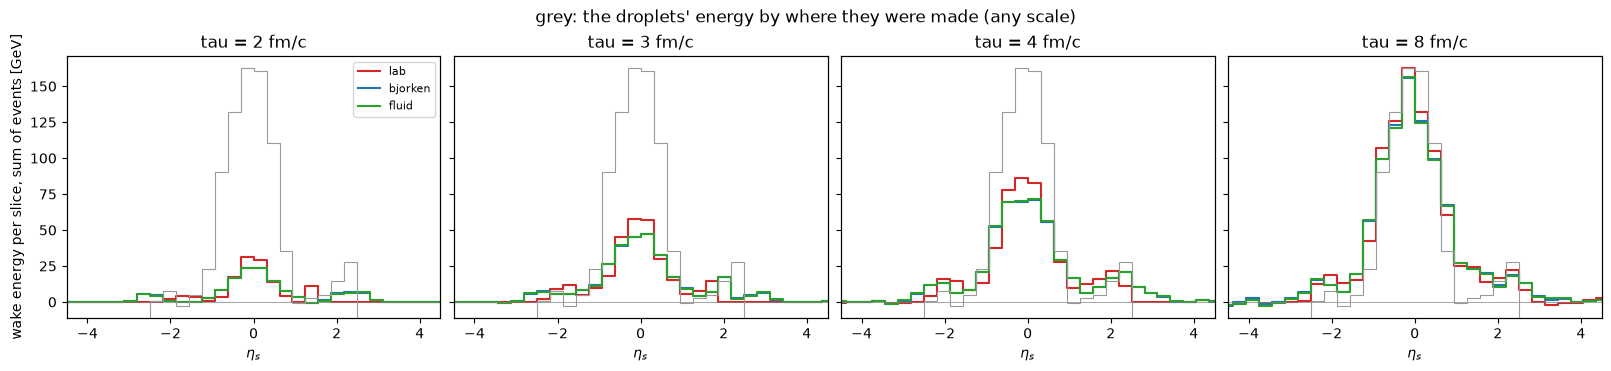

In [9]:
etas = z["etas"]
PT = list(z["prof_taus"])
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), constrained_layout=True, sharey=True)
for ax, t in zip(axes, (2.0, 3.0, 4.0, 8.0)):
    j = PT.index(t)
    for fr in FRAMES:
        p = np.nansum(z[f"{fr}/prof"][:, j], axis=0)
        ax.step(etas, p, where="mid", color=COL[fr], label=fr)
    ax.axhline(0, color="0.5", lw=0.5)
    ax.set(title=f"tau = {t:.0f} fm/c", xlabel=r"$\eta_s$", xlim=(-4.5, 4.5))
axes[0].set_ylabel("wake energy per slice, sum of events [GeV]"); axes[0].legend(fontsize=8)
de = etas[1] - etas[0]
h = hist.Hist(hist.axis.Variable(np.append(etas - de / 2, etas[-1] + de / 2), name="eta",
                                 label=r"$\eta_d$"))
h.fill(drops[:, 3], weight=E)
for ax in axes:
    ax2 = ax.twinx(); hep.histplot(h, ax=ax2, color="0.6", lw=0.8); ax2.set_yticks([])
fig.suptitle("grey: the droplets' energy by where they were made (any scale)");

**What to notice.**

- **The lab frame** puts more of the early wake at midrapidity (31 against 24 GeV in the
  central slice at $\tau = 2$ fm/c) and less at $\eta_s \approx 2$: it pulls forward droplets in.
- **By $\tau = 8$ fm/c** the profiles have nearly converged, but the lab frame keeps a little
  more at $|\eta_s| < 1$ (section 5.1).
- **Bjorken and fluid** are indistinguishable along $\eta_s$ at all times.

### 4.3 The wake in the transverse plane

The wake at midrapidity ($\Delta e$ summed over $|\eta_s| < 0.5$) of the event with the most
energy deposited there, in the three frames, and how much the maps differ event by event.

per event, |A - B| / |B| of the midrapidity maps (L2), median over events:


  tau 3 fm/c, bjorken vs lab: median 0.197, max 0.563 (25 events)


  tau 3 fm/c, fluid vs bjorken: median 0.177, max 0.520 (25 events)


  tau 6 fm/c, bjorken vs lab: median 0.160, max 0.441 (25 events)


  tau 6 fm/c, fluid vs bjorken: median 0.304, max 0.821 (25 events)


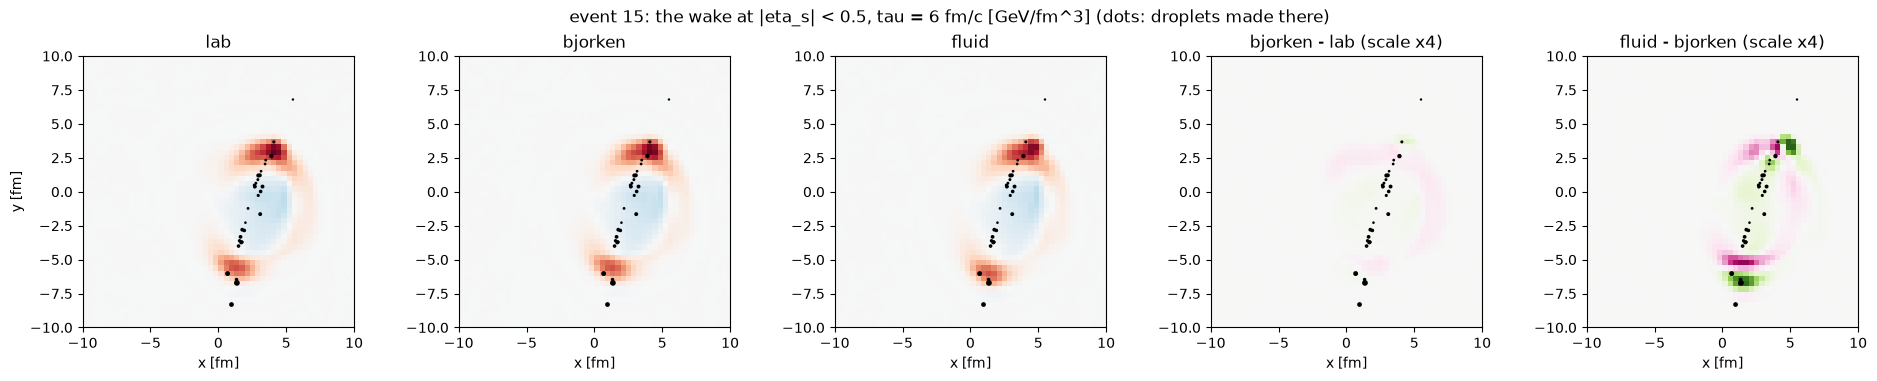

In [10]:
x, y = z["x"], z["y"]
MT = list(z["map_taus"])
e_mid = np.array([np.abs(E[(ev == i) & (np.abs(drops[:, 3]) < 0.5)]).sum() for i in range(nev)])
i_ev = int(np.argmax(e_mid))
j = MT.index(6.0)
fig, axes = plt.subplots(1, 5, figsize=(19, 3.7), constrained_layout=True)
maps = {fr: z[f"{fr}/map"][i_ev, j] for fr in FRAMES}
m = max(np.nanmax(np.abs(maps[fr])) for fr in FRAMES)
for ax, fr in zip(axes, FRAMES):
    ax.pcolormesh(x, y, maps[fr].T, cmap="RdBu_r", vmin=-m, vmax=m, shading="nearest")
    ax.set(title=f"{fr}", aspect=1, xlim=(-10, 10), ylim=(-10, 10), xlabel="x [fm]")
for ax, (a, b) in zip(axes[3:], (("bjorken", "lab"), ("fluid", "bjorken"))):
    if a in maps and b in maps:
        d = maps[a] - maps[b]
        im = ax.pcolormesh(x, y, d.T, cmap="PiYG", vmin=-m / 4, vmax=m / 4, shading="nearest")
        ax.set(title=f"{a} - {b} (scale x4)", aspect=1, xlim=(-10, 10), ylim=(-10, 10), xlabel="x [fm]")
dd = drops[(ev == i_ev) & (np.abs(drops[:, 3]) < 0.5)]
for ax in axes:
    ax.scatter(dd[:, 1], dd[:, 2], s=3 + 2 * np.abs(dd[:, 4]), c="k", lw=0)
axes[0].set_ylabel("y [fm]")
fig.suptitle(f"event {i_ev}: the wake at |eta_s| < 0.5, tau = 6 fm/c [GeV/fm^3] (dots: droplets made there)")

print("per event, |A - B| / |B| of the midrapidity maps (L2), median over events:")
for t in MT:
    jj = MT.index(t)
    for a, b in (("bjorken", "lab"), ("fluid", "bjorken")):
        r = [np.linalg.norm(z[f"{a}/map"][i, jj] - z[f"{b}/map"][i, jj]) / max(np.linalg.norm(z[f"{b}/map"][i, jj]), 1e-12)
             for i in range(nev) if np.isfinite(z[f"{a}/map"][i, jj]).all() and np.isfinite(z[f"{b}/map"][i, jj]).all()]
        print(f"  tau {t:.0f} fm/c, {a} vs {b}: median {np.median(r):.3f}, max {np.max(r):.3f} ({len(r)} events)")

**What to notice.**

- **Same structure, different details.** All three frames give the same Mach-cone and
  diffusion-wake structure, but the maps differ locally.
- **Bjorken against lab:** 16–20 % (L2, median over events), from the droplets the lab frame
  moved in $\eta_s$.
- **Fluid against bjorken:** 18 % at $\tau = 3$ and 30 % at $\tau = 6$ fm/c. The difference
  map is dipoles along the radial flow at the late droplets: the fluid frame deposits them
  0.3–0.8 fm further out. The total energy is the same (section 5.1); the energy is moved,
  not lost.

## 5. Wake observables

### 5.1 The hydro wake at midrapidity

The wake's energy at $|\eta_s| < 1$, summed over events, and per event against the Bjorken
frame. The three runs share every droplet, so the event-by-event differences are the frame's
alone; their spread over the 25 events gives the error of the mean difference.

 tau |       lab   bjorken     fluid | lab - bjorken  | fluid - bjorken   (per event, GeV)
   2 |      98.9      95.4      95.8 | +0.14 +- 0.15 | +0.02 +- 0.01   (25 events)
   3 |     223.7     207.3     208.3 | +0.66 +- 0.24 | +0.04 +- 0.02   (25 events)
   4 |     368.5     347.2     349.0 | +0.85 +- 0.23 | +0.07 +- 0.05   (25 events)
   6 |     567.6     538.4     539.0 | +1.17 +- 0.44 | +0.03 +- 0.11   (25 events)
   8 |     692.5     670.9     666.1 | +0.86 +- 0.32 | -0.19 +- 0.11   (25 events)


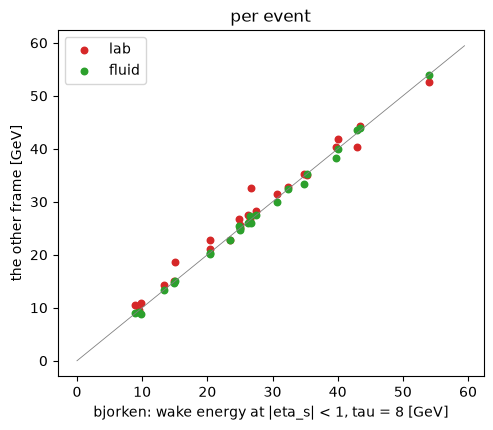

In [11]:
def paired(a, b):
    d = a - b
    d = d[np.isfinite(d)]
    return d.mean(), d.std(ddof=1) / np.sqrt(len(d)), len(d)

print(f"{'tau':>4} | " + " ".join(f"{fr:>9s}" for fr in FRAMES) + " | lab - bjorken  | fluid - bjorken   (per event, GeV)")
for t in (2.0, 3.0, 4.0, 6.0, 8.0):
    kk = int(np.argmin(np.abs(tau - t)))
    v = {fr: series(fr, "dE_win")[:, kk] for fr in FRAMES}
    s = " ".join(f"{np.nansum(v[fr]):9.1f}" for fr in FRAMES)
    a = paired(v["lab"], v["bjorken"]); b = paired(v["fluid"], v["bjorken"])
    print(f"{t:4.0f} | {s} | {a[0]:+5.2f} +- {a[1]:.2f} | {b[0]:+5.2f} +- {b[1]:.2f}   ({a[2]} events)")

k8 = int(np.argmin(np.abs(tau - 8.0)))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ref = series("bjorken", "dE_win")[:, k8]
for fr in ("lab", "fluid"):
    ax.scatter(ref, series(fr, "dE_win")[:, k8], color=COL[fr], label=fr, s=22)
lim = np.nanmax(ref) * 1.1
ax.plot([0, lim], [0, lim], color="0.5", lw=0.6)
ax.set(xlabel="bjorken: wake energy at |eta_s| < 1, tau = 8 [GeV]", ylabel="the other frame [GeV]",
       title="per event"); ax.legend();

**What to notice.**

- **The lab frame** gives a larger midrapidity wake, +0.9 GeV per event at $\tau = 8$ fm/c
  (+3 %, 2.7 standard deviations). It is the energy of forward droplets it pulled into the window.
  The 5-event set gave 6 %; with 25 events it is 3 %.
- **The fluid and Bjorken frames** agree within 0.1–0.2 GeV per event at all times, below 1 %.
  The transverse shift of section 4 does not change how much energy sits at midrapidity.

### 5.2 The hadronic wake

Charged hadrons from the jet leg's surface minus those from the background's (bulk jet −
background, correlated sampling: sample $k$ of each event paired with sample $k$ of its
background). Per event; the errors are each frame's own, from the per-sample differences.

per event, charged, |eta| < 1 (bulk jet - background):
  N             lab  11.89  bjorken  11.85  fluid  11.67   lab - bjorken +0.03 +- 0.35, fluid - bjorken -0.18 +- 0.29
  sum pT [GeV]  lab  10.08  bjorken  10.29  fluid   9.71   lab - bjorken -0.21 +- 0.24, fluid - bjorken -0.58 +- 0.17


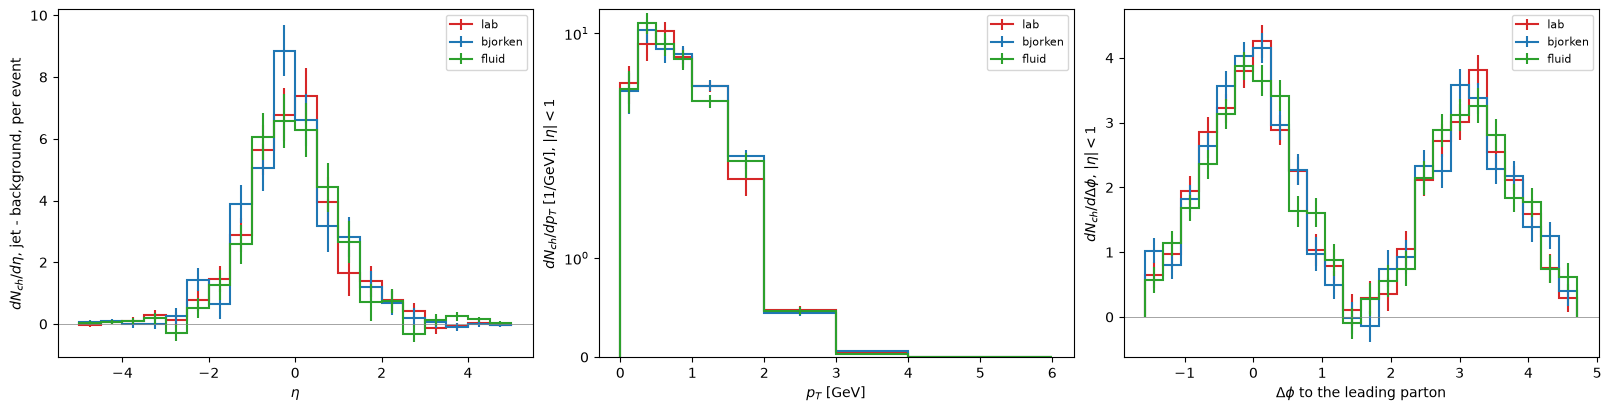

In [12]:
def plot_diff(ax, key, edges, xlabel, per_width=True, ratio_ax=None):
    w = np.diff(edges) if per_width else np.ones(len(edges) - 1)
    for fr in FRAMES:
        v, e = z[f"{fr}/{key}"]
        hep.histplot(v / w, edges, yerr=e / w, ax=ax, color=COL[fr], label=fr)
    ax.axhline(0, color="0.5", lw=0.5)
    ax.set(xlabel=xlabel)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
plot_diff(axes[0], "had_dndeta", z["eta_edges"], r"$\eta$")
axes[0].set(ylabel=r"$dN_{ch}/d\eta$, jet - background, per event")
plot_diff(axes[1], "had_pt", z["pt_edges"], r"$p_T$ [GeV]")
axes[1].set(ylabel=r"$dN_{ch}/dp_T$ [1/GeV], $|\eta| < 1$", yscale="symlog")
plot_diff(axes[2], "had_dphi", z["dphi_edges"], r"$\Delta\phi$ to the leading parton")
axes[2].set(ylabel=r"$dN_{ch}/d\Delta\phi$, $|\eta| < 1$")
for a in axes: a.legend(fontsize=8)

print("per event, charged, |eta| < 1 (bulk jet - background):")
for key, name in (("had_N_ev", "N"), ("had_sumpt_ev", "sum pT [GeV]")):
    v = {fr: z[f"{fr}/{key}"][:, 0] for fr in FRAMES}
    s = "  ".join(f"{fr} {v[fr].mean():6.2f}" for fr in FRAMES)
    a = paired(v["lab"], v["bjorken"]); b = paired(v["fluid"], v["bjorken"])
    print(f"  {name:13s} {s}   lab - bjorken {a[0]:+.2f} +- {a[1]:.2f}, fluid - bjorken {b[0]:+.2f} +- {b[1]:.2f}")

**What to notice.**

- **Shapes.** $dN/d\eta$, the $p_T$ spectrum and $dN/d\Delta\phi$ (the near-side peak and the
  away-side wake at $\Delta\phi \approx \pi$) have the same shape in all three frames, within
  this sample's errors.
- **Multiplicity.** The charged multiplicity of the wake at $|\eta| < 1$ is the same: 11.9,
  11.9 and 11.7 per event, with differences of 0.03 ± 0.35 and −0.18 ± 0.29.
- **Summed $p_T$.** In the fluid frame it is lower than in the Bjorken frame by
  0.58 ± 0.17 GeV per event (−6 %, 3.4 standard deviations of the event-by-event
  differences). Its $p_T$ spectrum is slightly softer (more hadrons below 0.5 GeV, fewer at
  1–1.5 GeV): deposits moved outward, into cooler fluid nearer the edge, make softer hadrons.
  With one background and 25 jets this is a hint, not a measurement.
- **Lab against bjorken:** at hadron level the two agree within errors (−0.21 ± 0.24 GeV).

## 6. Summary

In [13]:
k2, k4 = (int(np.argmin(np.abs(tau - t))) for t in (2.0, 4.0))
rows = []
for fr in FRAMES:
    b = col(fr, "bad_share")
    ok = np.isfinite(col(fr, "eta_mean"))
    t_, r_ = ratio_sum[(fr, "dE_full")]
    rows.append((fr,
                 f"{np.nansum(b * np.abs(E)) / np.abs(E[np.isfinite(b)]).sum():.1%}",
                 f"{r_[np.argmin(np.abs(t_ - 2))]:.2f} / {r_[np.argmin(np.abs(t_ - 4))]:.2f}",
                 f"{np.average(np.abs(col(fr, 'eta_mean') - drops[:, 3])[ok], weights=np.abs(E)[ok]):.2f}",
                 f"{np.nanmedian(col(fr, 'cells')):.0f}",
                 f"{np.nansum(series(fr, 'dE_win')[:, k8]):.0f}",
                 f"{z[f'{fr}/had_N_ev'][:, 0].mean():.2f}",
                 f"{z[f'{fr}/had_sumpt_ev'][:, 0].mean():.2f}"))
head = ("frame", "|E| uninvertible", "kept tau 2 / 4", "|d eta| centroid", "cells", "wake |eta_s|<1, tau 8 [GeV]",
        "N_ch wake", "sum pT wake [GeV]")
print(" | ".join(head)); print(" | ".join("---" for _ in head))
for r in rows: print(" | ".join(r))

frame | |E| uninvertible | kept tau 2 / 4 | |d eta| centroid | cells | wake |eta_s|<1, tau 8 [GeV] | N_ch wake | sum pT wake [GeV]
--- | --- | --- | --- | --- | --- | --- | ---
lab | 3.5% | 0.90 / 0.97 | 0.16 | 45 | 693 | 11.89 | 10.08
bjorken | 0.4% | 1.00 / 0.99 | 0.01 | 52 | 671 | 11.85 | 10.29
fluid | 1.6% | 1.00 / 1.00 | 0.02 | 50 | 666 | 11.67 | 9.71


**Conclusions (25 events, one background).**

1. **The lab frame is not usable away from midrapidity.**
   - It loses energy: up to half of an event's deposit early, 10 % of all of it at
     $\tau = 2$ fm/c, mostly through cells MUSIC cannot invert.
   - It displaces deposits toward midrapidity by up to 0.9 units, which inflates the
     midrapidity wake by 3 %.
2. **The Bjorken frame (the default) fixes both.**
   - Energy is kept within 1 % over the grid, and only 0.4 % of the energy goes into
     uninvertible cells.
   - Every droplet deposits around its own $\eta_s$.
3. **The fluid frame agrees with the Bjorken frame along the beam axis and in the energy
   bookkeeping** (midrapidity wake within 1 %).
   - It moves late deposits outward with the radial flow (up to 0.8 fm) and contracts them.
   - That changes the local wake maps by 20–30 % and the uninvertible share to 1.6 %.
   - At hadron level the wake's multiplicity is unchanged; its summed $p_T$ is 6 % lower in
     this sample.
4. **Choosing between bjorken and fluid** is a physics choice, not a numerical one.
   - The fluid frame is what the liquefier's paper asks for: the diffusion isotropic in the
     medium's rest frame, with its flow treated properly.
   - The effects are transverse and local, and at a few percent in the hadron wake.
   - FastHydro has no fluid frame yet, so MUSIC and FastHydro wake files compare directly
     only in the bjorken and lab frames.